# Time formats
- Man's inventivness regarding ways of representing dates and time points is truly inspiring ... and a source of headache.  
  
__Oracle suggests:__  
- time formats as (possible subsets of) HH:MM:SS XM (XM = AM/PM), with possible separators: ".", ",", "-", " ", ":"
- 18 different [date formats](https://docs.oracle.com/cd/E41183_01/DR/Date_Format_Types.html).
  
__Unix timestamp__  
- The number of seconds (and milli-, micro- and nanoseconds) since 1 January 1970 at the UTC timezone.
- Examples at [https://www.unixtimestamp.com/](https://www.unixtimestamp.com/)

In [1]:
from datetime import datetime

# Getting the current date and time
dt = datetime.now()

# getting the timestamp
ts = datetime.timestamp(dt)

print("Date and time is:", dt)
print("Timestamp is:", ts)

Date and time is: 2026-10-22 08:36:03.394162
Timestamp is: 1792650963.394162


## ISO standard
[W3.org: ISO 8601](https://www.w3.org/TR/NOTE-datetime) and [Wikipedia: ISO 8601](https://en.wikipedia.org/wiki/ISO_8601)
- Year:
  - YYYY (e.g., 1997)
- Year and month:
  - YYYY-MM (e.g., 1997-07)
- Complete date:
  - YYYY-MM-DD (e.g., 1997-07-16)
- Complete date plus hours and minutes:
  - YYYY-MM-DDThh:mmTZD (e.g., 1997-07-16T19:20+01:00)
- Complete date plus hours, minutes and seconds:
  - YYYY-MM-DDThh:mm:ssTZD (e.g., 1997-07-16T19:20:30+01:00)
- Complete date plus hours, minutes, seconds and a decimal fraction of a
second
  - YYYY-MM-DDThh:mm:ss.sTZD (e.g., 1997-07-16T19:20:30.45+01:00)
  
where:
- YYYY = four-digit year
- MM   = two-digit month (01=January, etc.)
- DD   = two-digit day of month (01 through 31)
- hh   = two digits of hour (00 through 23) (am/pm NOT allowed)
- mm   = two digits of minute (00 through 59)
- ss   = two digits of second (00 through 59)
- s    = one or more digits representing a decimal fraction of a second
- TZD  = time zone designator (Z or +hh:mm or -hh:mm)

## Time conversion
- Basic time formats can be converted using Python's [datetime library](https://docs.python.org/3/library/datetime.html#strftime-and-strptime-behavior).
- Pandas has its own [datetime converter](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html).

In [2]:
now = datetime.now()
print("Original:", now)
formatted = now.strftime("%d/%m-%Y %H:%M:%S")
print("An arbitrary format:", formatted)

reformatted = datetime.strptime(formatted, "%d/%m-%Y %H:%M:%S")
print("Reformatted to the standard:", reformatted)

Original: 2026-10-22 08:36:03.418135
An arbitrary format: 22/10-2026 08:36:03
Reformatted to the standard: 2026-10-22 08:36:03


## Exercise
- Read the _white\_rabbit.dat_ data using Pandas.
- Convert the columns into standard Python format datetimes in the same timezone.
- Concatenate the three columns into a single time series.
- Convert it to your local timezone.
- Confirm vilsually that you have handled each series correctly by plotting the resulting datetimes, achieving a perfectly straight line.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Les datafilen
path = "../../data/white_rabit.dat"
df = pd.read_csv(path, skiprows=1, sep=";")

df

,date_A,date_B,date_C
0,27.02.23 01:00:00+01:00,01:00:00 03.08-2023,02:00 17/03-2023
1,27.02.23 22:42:00+01:00,22:42:00 03.08-2023,23:42 17/03-2023
2,28.02.23 20:24:00+01:00,20:24:00 03.09-2023,21:24 18/03-2023
3,01.03.23 18:06:00+01:00,18:06:00 03.10-2023,19:06 19/03-2023
4,02.03.23 15:48:00+01:00,15:48:00 03.11-2023,16:48 20/03-2023
5,03.03.23 13:30:00+01:00,13:30:00 03.12-2023,14:30 21/03-2023
6,04.03.23 11:12:00+01:00,11:12:00 03.13-2023,12:12 22/03-2023
7,05.03.23 08:54:00+01:00,08:54:00 03.14-2023,09:54 23/03-2023
8,06.03.23 06:36:00+01:00,06:36:00 03.15-2023,07:36 24/03-2023
9,07.03.23 04:18:00+01:00,04:18:00 03.16-2023,05:18 25/03-2023


In [8]:
# date_A har allerede tidssone (+01:00)
date_a = pd.to_datetime(
    df["date_A"],
    format="%d.%m.%y %H:%M:%S%z",
    utc=True,
)

# date_B mangler tidssone, og skal derfor tolkes som UTC
date_b = pd.to_datetime(
    df["date_B"],
    format="%H:%M:%S %m.%d-%Y",
    utc=True,
)

# date_C mangler sekunder og tidssone, og skal tolkes som UTC
date_c = pd.to_datetime(
    df["date_C"],
    format="%H:%M %d/%m-%Y",
    utc=True,
)

df["date_A_utc"] = date_a
df["date_B_utc"] = date_b
df["date_C_utc"] = date_c

df

,date_A,date_B,date_C,date_A_utc,date_B_utc,date_C_utc
0,27.02.23 01:00:00+01:00,01:00:00 03.08-2023,02:00 17/03-2023,2023-02-27 00:00:00+00:00,2023-03-08 01:00:00+00:00,2023-03-17 02:00:00+00:00
1,27.02.23 22:42:00+01:00,22:42:00 03.08-2023,23:42 17/03-2023,2023-02-27 21:42:00+00:00,2023-03-08 22:42:00+00:00,2023-03-17 23:42:00+00:00
2,28.02.23 20:24:00+01:00,20:24:00 03.09-2023,21:24 18/03-2023,2023-02-28 19:24:00+00:00,2023-03-09 20:24:00+00:00,2023-03-18 21:24:00+00:00
3,01.03.23 18:06:00+01:00,18:06:00 03.10-2023,19:06 19/03-2023,2023-03-01 17:06:00+00:00,2023-03-10 18:06:00+00:00,2023-03-19 19:06:00+00:00
4,02.03.23 15:48:00+01:00,15:48:00 03.11-2023,16:48 20/03-2023,2023-03-02 14:48:00+00:00,2023-03-11 15:48:00+00:00,2023-03-20 16:48:00+00:00
5,03.03.23 13:30:00+01:00,13:30:00 03.12-2023,14:30 21/03-2023,2023-03-03 12:30:00+00:00,2023-03-12 13:30:00+00:00,2023-03-21 14:30:00+00:00
6,04.03.23 11:12:00+01:00,11:12:00 03.13-2023,12:12 22/03-2023,2023-03-04 10:12:00+00:00,2023-03-13 11:12:00+00:00,2023-03-22 12:12:00+00:00
7,05.03.23 08:54:00+01:00,08:54:00 03.14-2023,09:54 23/03-2023,2023-03-05 07:54:00+00:00,2023-03-14 08:54:00+00:00,2023-03-23 09:54:00+00:00
8,06.03.23 06:36:00+01:00,06:36:00 03.15-2023,07:36 24/03-2023,2023-03-06 05:36:00+00:00,2023-03-15 06:36:00+00:00,2023-03-24 07:36:00+00:00
9,07.03.23 04:18:00+01:00,04:18:00 03.16-2023,05:18 25/03-2023,2023-03-07 03:18:00+00:00,2023-03-16 04:18:00+00:00,2023-03-25 05:18:00+00:00


In [12]:
time_series = pd.concat(
    [
        df["date_A_utc"],
        df["date_B_utc"],
        df["date_C_utc"],
    ],
    ignore_index=True,
).sort_values()

time_series = time_series.reset_index(drop=True)

time_series.head()

local_time_series = time_series.dt.tz_convert("Europe/Berlin")
local_time_series.head()

0   2023-02-27 01:00:00+01:00
1   2023-02-27 22:42:00+01:00
2   2023-02-28 20:24:00+01:00
3   2023-03-01 18:06:00+01:00
4   2023-03-02 15:48:00+01:00
dtype: datetime64[us, Europe/Berlin]

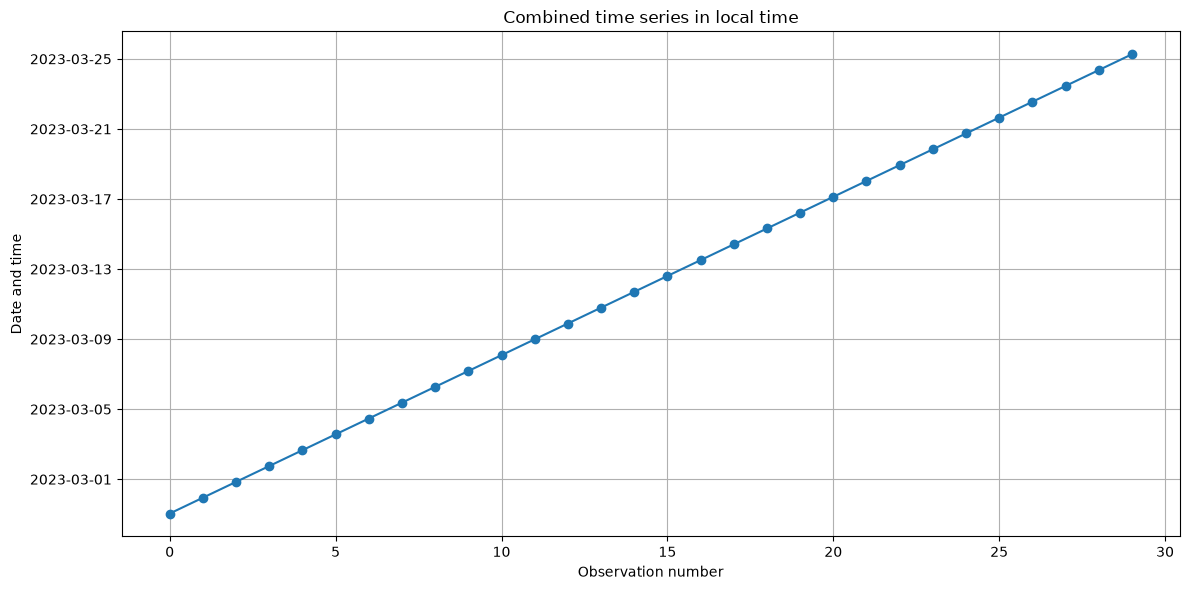

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    range(len(local_time_series)),
    local_time_series,
    marker="o",
    linestyle="-",
)

plt.xlabel("Observation number")
plt.ylabel("Date and time")
plt.title("Combined time series in local time")
plt.grid(True)
plt.tight_layout()
plt.show()

```{seealso} 
:class: tip

## Resources
- [Oracle date formats](https://docs.oracle.com/cd/E41183_01/DR/Date_Format_Types.html).
- [Unix timestamp](https://www.unixtimestamp.com/)
- [W3.org: ISO 8601](https://www.w3.org/TR/NOTE-datetime) 
- [Wikipedia: ISO 8601](https://en.wikipedia.org/wiki/ISO_8601)
- [Python datetime library](https://docs.python.org/3/library/datetime.html#strftime-and-strptime-behavior).
- [Pandas datetime converter](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html).